In [1]:
import os
import glob
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
flicker_df = pd.read_csv("XPQRS/Flicker.csv")
flicker_with_sag_df = pd.read_csv("XPQRS/Flicker_with_Sag.csv")
flicker_with_swell_df = pd.read_csv("XPQRS/Flicker_with_Swell.csv")
harmonics_df = pd.read_csv("XPQRS/Harmonics.csv")
harmonics_with_sag_df = pd.read_csv("XPQRS/Harmonics_with_Sag.csv")
harmonics_with_swell_df = pd.read_csv("XPQRS/Harmonics_with_Swell.csv")
interruption_df = pd.read_csv("XPQRS/Interruption.csv")
notch_df = pd.read_csv("XPQRS/Notch.csv")
oscillatory_transient_df = pd.read_csv("XPQRS/Oscillatory_Transient.csv")
pure_sinusoidal_df = pd.read_csv("XPQRS/Pure_Sinusoidal.csv")
sag_df = pd.read_csv("XPQRS/Sag.csv")
sag_with_harmonics_df = pd.read_csv("XPQRS/Sag_with_Harmonics.csv")
sag_with_oscillatory_transient_df = pd.read_csv("XPQRS/Sag_with_Oscillatory_Transient.csv")
swell_df = pd.read_csv("XPQRS/Swell.csv")
swell_with_harmonics_df = pd.read_csv("XPQRS/Swell_with_Harmonics.csv")
swell_with_oscillatory_transient_df = pd.read_csv("XPQRS/Swell_with_Oscillatory_Transient.csv")
transient_df = pd.read_csv("XPQRS/Transient.csv")

In [3]:
flicker_df.head()

,0.998803016326019,1.00093035393725,0.999105553138814,0.993327593431853,0.983611102360254,0.969986334141963,0.952499086219062,0.931210553880993,0.906197123362766,0.877550104066715,...,0.839519074523991,0.880687604855291,0.918410664527645,0.952534833742929,0.982920921603107,1.00944454022342,1.03199661970499,1.05048386180353,1.0648291303785,1.07497177696332
0,0.626540,0.576782,0.524674,0.470417,0.414224,0.356313,0.296911,0.236251,0.174570,0.112111,...,1.015561,0.996524,0.973534,0.946680,0.916066,0.881813,0.844053,0.802935,0.758621,0.711284
1,0.088343,0.025671,-0.037334,-0.100424,-0.163349,-0.225856,-0.287697,-0.348623,-0.408388,-0.466749,...,0.720869,0.667349,0.611201,0.552653,0.491943,0.429319,0.365034,0.299349,0.232530,0.164849
2,0.067605,0.130368,0.192856,0.254818,0.316005,0.376170,0.435068,0.492458,0.548104,0.601776,...,-0.542400,-0.486215,-0.428306,-0.368910,-0.308271,-0.246637,-0.184257,-0.121383,-0.058267,0.004839
3,0.968689,0.953218,0.933902,0.910800,0.883986,0.853551,0.819599,0.782252,0.741643,0.697919,...,1.002791,1.024722,1.042525,1.056137,1.065512,1.070622,1.071457,1.068024,1.060349,1.048474
4,0.952476,0.970862,0.985453,0.996180,1.002994,1.005857,1.004748,0.999663,0.990612,0.977622,...,0.639812,0.693569,0.744618,0.792753,0.837779,0.879515,0.917793,0.952457,0.983368,1.010399


In [4]:
harmonics_df.head()

,-0.118791500597708,-0.0330210561312059,0.0453727222087239,0.118880097999327,0.189827979991755,0.259670491326418,0.328563907503245,0.395309361960064,0.457665688412558,0.512954386122759,...,-0.965762576704286,-0.956670984603969,-0.918905250771148,-0.853763028997658,-0.765551341518573,-0.660702560016634,-0.546623048809677,-0.430490943035578,-0.318217742208638,-0.213747029666977
0,-0.865092,-0.884290,-0.910850,-0.944373,-0.982522,-1.021550,-1.057052,-1.084784,-1.101398,-1.104960,...,-0.325717,-0.439215,-0.544652,-0.636085,-0.709740,-0.764458,-0.801703,-0.825142,-0.839887,-0.851517
1,-0.469072,-0.520378,-0.547554,-0.552598,-0.540502,-0.518550,-0.495253,-0.479090,-0.477261,-0.494665,...,0.372057,0.328879,0.273895,0.204274,0.119345,0.020977,-0.086463,-0.196599,-0.301911,-0.394861
2,0.558254,0.488038,0.390984,0.276215,0.155178,0.039521,-0.061007,-0.140245,-0.196603,-0.233145,...,0.589997,0.516901,0.471913,0.457519,0.470831,0.504039,0.545729,0.582860,0.603021,0.596570
3,1.266193,1.276133,1.248968,1.193697,1.122143,1.046834,0.978880,0.926216,0.892529,0.877012,...,0.232490,0.259006,0.320035,0.416696,0.544288,0.692893,0.848867,0.996961,1.122714,1.214692
4,0.595707,0.555276,0.492447,0.410535,0.315070,0.212770,0.110412,0.013785,-0.073080,-0.148312,...,0.715067,0.639192,0.583845,0.551847,0.542415,0.551313,0.571536,0.594426,0.611007,0.613349


In [5]:
harmonics_df.shape

(999, 100)

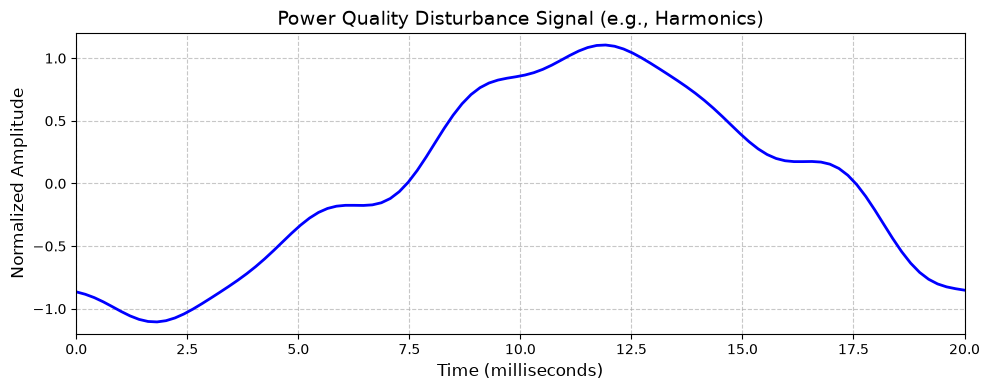

In [6]:

# 1. Load one of the dataset files (e.g., 'Sag.csv')
# Make sure the CSV file is in the same directory as your notebook
df = harmonics_df

# 2. Select a single row to visualize (e.g., row index 0)
signal_row = df.iloc[0].values

# 3. Create a time axis
# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 4. Plot the wave using Matplotlib
plt.figure(figsize=(10, 4))
plt.plot(time_axis, signal_row, color='b', linewidth=2)

# 5. Format the plot
plt.title("Power Quality Disturbance Signal (e.g., Harmonics)", fontsize=14)
plt.xlabel("Time (milliseconds)", fontsize=12)
plt.ylabel("Normalized Amplitude", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Ensure the y-axis shows the full -1 to 1 normalized range (plus a little padding)
plt.ylim(-1.2, 1.2)
plt.xlim(0, 20)

plt.tight_layout()
plt.show()

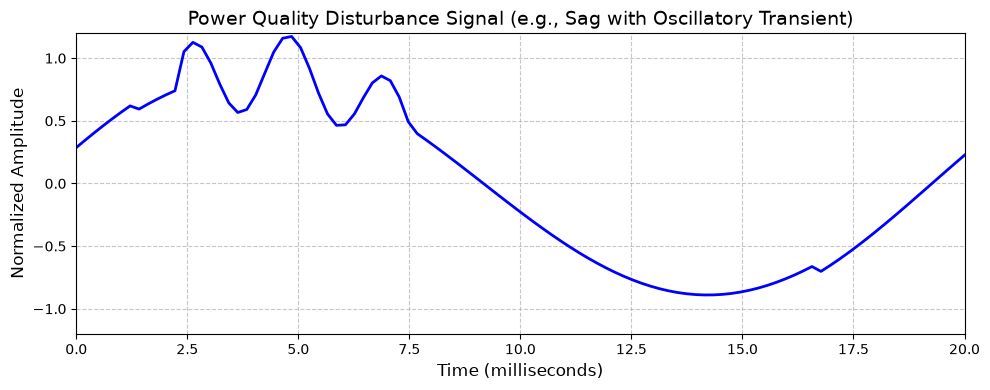

In [7]:

# 1. Load one of the dataset files (e.g., 'Sag.csv')
# Make sure the CSV file is in the same directory as your notebook
df = sag_with_oscillatory_transient_df

# 2. Select a single row to visualize (e.g., row index 0)
signal_row = df.iloc[0].values

# 3. Create a time axis
# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 4. Plot the wave using Matplotlib
plt.figure(figsize=(10, 4))
plt.plot(time_axis, signal_row, color='b', linewidth=2)

# 5. Format the plot
plt.title("Power Quality Disturbance Signal (e.g., Sag with Oscillatory Transient)", fontsize=14)
plt.xlabel("Time (milliseconds)", fontsize=12)
plt.ylabel("Normalized Amplitude", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Ensure the y-axis shows the full -1 to 1 normalized range (plus a little padding)
plt.ylim(-1.2, 1.2)
plt.xlim(0, 20)

plt.tight_layout()
plt.show()

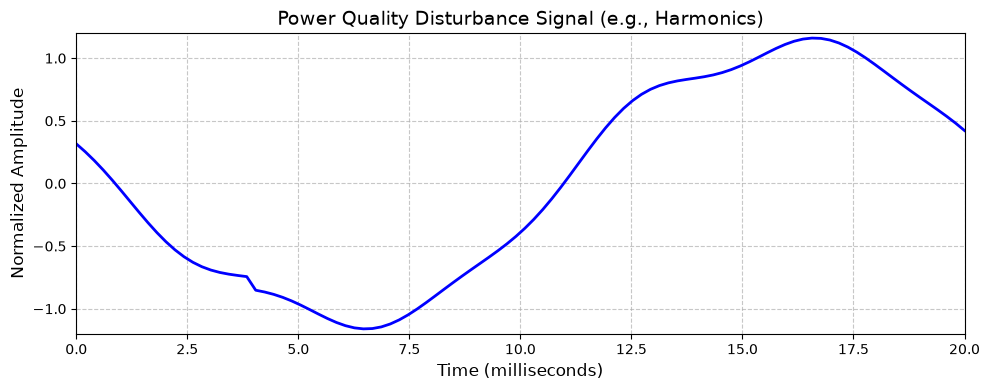

In [8]:

# 1. Load one of the dataset files (e.g., 'Sag.csv')
# Make sure the CSV file is in the same directory as your notebook
df = harmonics_with_swell_df

# 2. Select a single row to visualize (e.g., row index 0)
signal_row = df.iloc[1].values

# 3. Create a time axis
# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 4. Plot the wave using Matplotlib
plt.figure(figsize=(10, 4))
plt.plot(time_axis, signal_row, color='b', linewidth=2)

# 5. Format the plot
plt.title("Power Quality Disturbance Signal (e.g., Harmonics)", fontsize=14)
plt.xlabel("Time (milliseconds)", fontsize=12)
plt.ylabel("Normalized Amplitude", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Ensure the y-axis shows the full -1 to 1 normalized range (plus a little padding)
plt.ylim(-1.2, 1.2)
plt.xlim(0, 20)

plt.tight_layout()
plt.show()

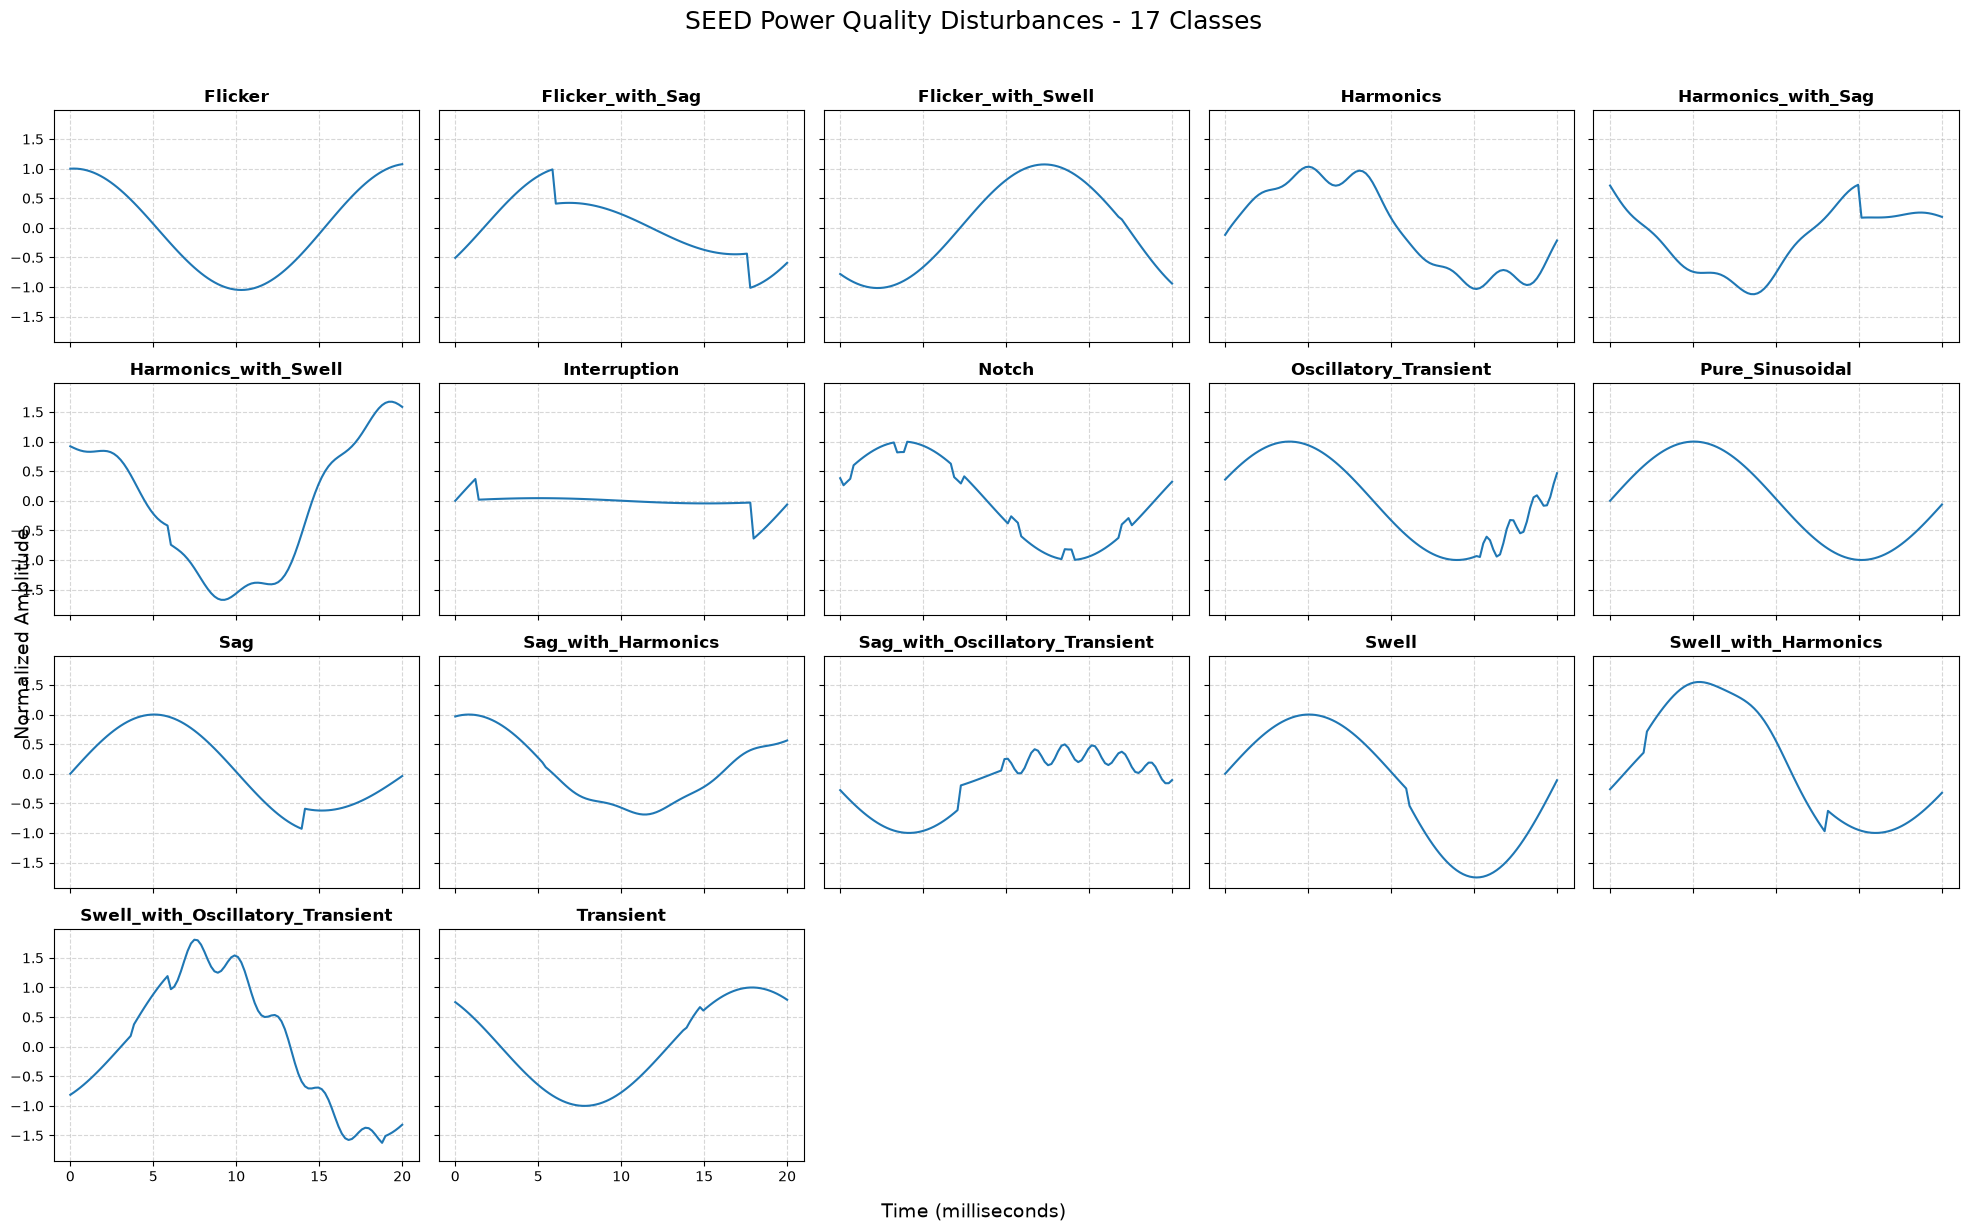

In [9]:

csv_files = glob.glob('XPQRS/*.csv')
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(20, 12), sharex=True, sharey=True)

# Flatten the 2D axes array into a 1D list so we can loop through it easily
axes = axes.flatten()

# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 3. Loop through each file and plot its first row
for i, file in enumerate(csv_files):
    if i >= 17:  # Stop if there are extra CSVs in the folder
        break
        
    # Extract the class name from the filename (e.g., 'Sag.csv' -> 'Sag')
    class_name = os.path.splitext(os.path.basename(file))[0]
    
    # Read ONLY the first row to save memory and time
    df = pd.read_csv(file, header=None, nrows=1)
    signal_row = df.iloc[0].values
    
    # Plot on the specific subplot grid item
    ax = axes[i]
    ax.plot(time_axis, signal_row, color='#1f77b4', linewidth=1.5)
    
    # Format the individual subplot
    ax.set_title(class_name, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

# 4. Remove the empty subplots (indices 17, 18, and 19)
for j in range(len(csv_files), len(axes)):
    fig.delaxes(axes[j])

# 5. Add global labels and adjust layout
fig.supxlabel('Time (milliseconds)', fontsize=14)
fig.supylabel('Normalized Amplitude', fontsize=14)
fig.suptitle('SEED Power Quality Disturbances - 17 Classes', fontsize=18, y=1.02)

plt.tight_layout()
plt.show()

In [10]:
def rename_columns(df):
    # Example: Rename columns as 'Column_1', 'Column_2', etc.
    new_column_names = [f"Column_{i+1}" for i in range(len(df.columns))]
    df.columns = new_column_names
    return df

In [11]:
flicker_df = rename_columns(flicker_df)
flicker_with_sag_df = rename_columns(flicker_with_sag_df)
flicker_with_swell_df = rename_columns(flicker_with_swell_df)
harmonics_df = rename_columns(harmonics_df)
harmonics_with_sag_df = rename_columns(harmonics_with_sag_df)
harmonics_with_swell_df = rename_columns(harmonics_with_swell_df)
interruption_df = rename_columns(interruption_df)
notch_df = rename_columns(notch_df)
oscillatory_transient_df = rename_columns(oscillatory_transient_df)
pure_sinusoidal_df = rename_columns(pure_sinusoidal_df)
sag_df = rename_columns(sag_df)
sag_with_harmonics_df = rename_columns(sag_with_harmonics_df)
sag_with_oscillatory_transient_df = rename_columns(sag_with_oscillatory_transient_df)
swell_df = rename_columns(swell_df)
swell_with_harmonics_df = rename_columns(swell_with_harmonics_df)
swell_with_oscillatory_transient_df = rename_columns(swell_with_oscillatory_transient_df)
transient_df = rename_columns(transient_df)

In [12]:
flicker_df.head()

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_91,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100
0,0.626540,0.576782,0.524674,0.470417,0.414224,0.356313,0.296911,0.236251,0.174570,0.112111,...,1.015561,0.996524,0.973534,0.946680,0.916066,0.881813,0.844053,0.802935,0.758621,0.711284
1,0.088343,0.025671,-0.037334,-0.100424,-0.163349,-0.225856,-0.287697,-0.348623,-0.408388,-0.466749,...,0.720869,0.667349,0.611201,0.552653,0.491943,0.429319,0.365034,0.299349,0.232530,0.164849
2,0.067605,0.130368,0.192856,0.254818,0.316005,0.376170,0.435068,0.492458,0.548104,0.601776,...,-0.542400,-0.486215,-0.428306,-0.368910,-0.308271,-0.246637,-0.184257,-0.121383,-0.058267,0.004839
3,0.968689,0.953218,0.933902,0.910800,0.883986,0.853551,0.819599,0.782252,0.741643,0.697919,...,1.002791,1.024722,1.042525,1.056137,1.065512,1.070622,1.071457,1.068024,1.060349,1.048474
4,0.952476,0.970862,0.985453,0.996180,1.002994,1.005857,1.004748,0.999663,0.990612,0.977622,...,0.639812,0.693569,0.744618,0.792753,0.837779,0.879515,0.917793,0.952457,0.983368,1.010399


In [13]:
flicker_df['class'] = 'Flicker'
flicker_with_sag_df['class'] = 'Flicker with Sag'
flicker_with_swell_df['class'] = 'Flicker with Swell'
harmonics_df['class'] = 'Harmonics' 
harmonics_with_sag_df['class'] = 'Harmonics with Sag'
harmonics_with_swell_df['class'] = 'Harmonics with Swell'
interruption_df['class'] = 'Interruption'
notch_df['class'] = 'Notch'
oscillatory_transient_df['class'] = 'Oscillatory Transient'
pure_sinusoidal_df['class'] = 'Pure Sinusoidal'
sag_df['class'] = 'Sag'
sag_with_harmonics_df['class'] = 'Sag with Harmonics'
sag_with_oscillatory_transient_df['class'] = 'Sag with Oscillatory'
swell_df['class'] = 'Swell'
swell_with_harmonics_df['class'] = 'Swell with Harmonics'
swell_with_oscillatory_transient_df['class'] = 'Swell with Oscillatory Transient'
transient_df['class'] = 'Transient'

In [14]:
swell_df.head(1)

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100,class
0,0,0.062791,0.125333,0.187381,0.24869,0.309017,0.368125,0.425779,0.481754,0.535827,...,-0.535827,-0.481754,-0.425779,-0.368125,-0.309017,-0.24869,-0.187381,-0.125333,-0.062791,Swell


In [15]:
combined_df = pd.concat([flicker_df, flicker_with_sag_df, flicker_with_swell_df, harmonics_df, harmonics_with_sag_df, harmonics_with_swell_df, interruption_df, notch_df, oscillatory_transient_df, pure_sinusoidal_df, sag_df, sag_with_harmonics_df,sag_with_oscillatory_transient_df, swell_df,swell_with_harmonics_df, swell_with_oscillatory_transient_df, transient_df], axis=0)
combined_df.shape

(16983, 101)

In [ ]:
resample_df = combined_df.sample(frac=1,random_state=42).reset_index(drop=True)
resample_df.head()         
# resample_df.to_csv("PQD.csv")